# Bagging Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md) (bagging = **b**ootstrap **agg**regat**ing**).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports) and the "two datasets" cell. After that, run the labs in order
   (`Shift + Enter` cell by cell) or **Run All**. Labs only reuse data from *earlier* labs, so top-to-bottom always works.
2. Look at the output and **guess what it means before reading the "How to read this" box**.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it proves |
|---|---|---|
| **A. How bagging works** | 1 – 6 | the hand example; bootstrap samples hold ≈ 63.2 % of the rows; one deep tree is unstable; how predictions are combined; the variance formula $\rho\sigma^2 + (1-\rho)\sigma^2/B$; out-of-bag (OOB) predictions |
| **B. Why it is useful** | 7 – 15 | variance drops while bias stays; more trees never over-fit; OOB ≈ cross-validation; bagging vs pasting; per-tree vs single-tree; error correlations; random subspaces/patches; feature importances |
| **C. Where it fails** | 16 – 19 | stable or high-bias base models; extrapolation (the bad-fit dataset); small data; cost and interpretability |

All data is generated in this notebook (or by scikit-learn's `make_*` functions) — **no internet needed**.

In [1]:
import pathlib
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

from sklearn.base import clone
from sklearn.datasets import make_classification, make_friedman1
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, precision_recall_fscore_support, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})


def per_tree_predictions(bag, X):
    """One row per tree: tree b's prediction for every row of X (each tree only sees its own feature subset)."""
    return np.array([tree.predict(X[:, feats]) for tree, feats in zip(bag.estimators_, bag.estimators_features_)])

## The two datasets

* **Good fit — `good_fit.csv`:** one input `x1` between 0 and 10, and a wiggly target
  $y = \sin(x) + 0.5\sin(3x) + \text{noise}$ (noise standard deviation 0.35). A single deep tree chases the noise; an
  average of many trees smooths it. Used in Part B.
* **Bad fit — `bad_fit.csv`:** a straight-line trend $y = 1 + 0.8x + \text{noise}$ (noise sd 0.5). We train only on
  $x < 6$ and ask for predictions at $6 \le x \le 10$, i.e. **outside** the training range. Trees cannot extrapolate,
  and averaging trees does not fix that. Used in Part C.

good fit: (300, 1)  bad fit: (200, 1)
data/bad_fit.csv 3.1 KB
data/good_fit.csv 5.0 KB


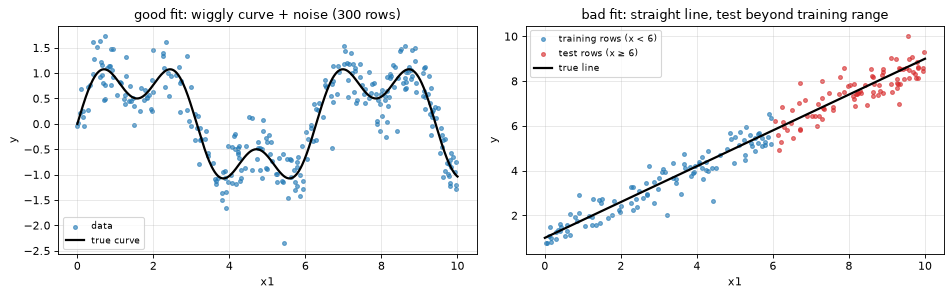

In [2]:
DATA = pathlib.Path("data")
DATA.mkdir(exist_ok=True)


def good_fit_truth(x):
    return np.sin(x) + 0.5 * np.sin(3 * x)


def make_good_fit(seed=0, n=300, noise=0.35, path=None):
    """Noisy wiggly 1-D regression: x ~ Uniform(0, 10), y = truth(x) + Normal(0, noise)."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 10, n)
    y = good_fit_truth(x) + rng.normal(0, noise, n)
    if path is not None:
        np.savetxt(path, np.column_stack([x, y]), delimiter=",", header="x1,y", comments="", fmt="%.6g")
    return x[:, None], y


def bad_fit_truth(x):
    return 1.0 + 0.8 * x


def make_bad_fit(seed=0, n=200, noise=0.5, path=None):
    """Straight-line trend: x ~ Uniform(0, 10), y = 1 + 0.8 x + Normal(0, noise). Train on x < 6 only."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 10, n)
    y = bad_fit_truth(x) + rng.normal(0, noise, n)
    if path is not None:
        np.savetxt(path, np.column_stack([x, y]), delimiter=",", header="x1,y", comments="", fmt="%.6g")
    return x[:, None], y


X_good, y_good = make_good_fit(seed=0, path=DATA / "good_fit.csv")
X_bad, y_bad = make_bad_fit(seed=0, path=DATA / "bad_fit.csv")
print("good fit:", X_good.shape, " bad fit:", X_bad.shape)
for f in sorted(DATA.glob("*.csv")):
    print(f, f"{f.stat().st_size / 1024:.1f} KB")

x_plot = np.linspace(0, 10, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(X_good[:, 0], y_good, s=12, alpha=0.6, label="data")
axes[0].plot(x_plot, good_fit_truth(x_plot), "k", lw=2, label="true curve")
axes[0].set_title("good fit: wiggly curve + noise (300 rows)")
in_train = X_bad[:, 0] < 6
axes[1].scatter(X_bad[in_train, 0], y_bad[in_train], s=12, alpha=0.6, label="training rows (x < 6)")
axes[1].scatter(X_bad[~in_train, 0], y_bad[~in_train], s=12, alpha=0.6, color="tab:red", label="test rows (x ≥ 6)")
axes[1].plot(x_plot, bad_fit_truth(x_plot), "k", lw=2, label="true line")
axes[1].set_title("bad fit: straight line, test beyond training range")
for ax in axes:
    ax.set_xlabel("x1"); ax.set_ylabel("y"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# Part A — How bagging works

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README section 5 number by number: 6 training rows, 3 bootstrap samples, one **stump** (a tree
with a single split) per sample, the averaged prediction, and the out-of-bag (OOB) rows of each sample.

A bootstrap sample is written as the list of row numbers that were drawn (1-based, like the README). scikit-learn's
`BaggingRegressor` passes such a sample to each tree as **counts** (`sample_weight` = how many times each row was
drawn); we do exactly the same here.

In [3]:
x_toy = np.arange(1, 7, dtype=float)                 # rows 1..6 have x = 1..6
y_toy = np.array([1, 3, 2, 6, 7, 5], dtype=float)
X_toy = x_toy[:, None]
samples_toy = [np.array([1, 1, 4, 4, 5, 5]),         # bootstrap sample 1 (row numbers drawn)
               np.array([2, 2, 3, 3, 4, 6]),         # bootstrap sample 2
               np.array([1, 1, 3, 3, 5, 5])]         # bootstrap sample 3


def weighted_sse(x, y, counts, threshold):
    """Squared error of a stump split at `threshold`, each row counted `counts` times."""
    total = 0.0
    for side in (x <= threshold, x > threshold):
        w, v = counts[side], y[side]
        mean = np.sum(w * v) / np.sum(w)
        total += np.sum(w * (v - mean) ** 2)
    return total


counts_toy, stumps_toy = [], []
for b, rows in enumerate(samples_toy, start=1):
    counts = np.bincount(rows - 1, minlength=6)       # how often each row was drawn
    inbag = np.flatnonzero(counts)
    candidates = (x_toy[inbag[:-1]] + x_toy[inbag[1:]]) / 2   # midpoints between neighbouring in-bag x values
    stump = DecisionTreeRegressor(max_depth=1).fit(X_toy, y_toy, sample_weight=counts)
    counts_toy.append(counts); stumps_toy.append(stump)
    print(f"sample {b}: rows {rows.tolist()}  counts {counts.tolist()}  OOB rows {(np.flatnonzero(counts == 0) + 1).tolist()}")
    for t in candidates:
        print(f"    split at x <= {t:.1f}: SSE = {weighted_sse(x_toy, y_toy, counts, t):.3f}")
    print(f"    sklearn stump: threshold {stump.tree_.threshold[0]:.1f}, "
          f"left leaf {stump.tree_.value[1, 0, 0]:.2f}, right leaf {stump.tree_.value[2, 0, 0]:.2f}")

sample 1: rows [1, 1, 4, 4, 5, 5]  counts [2, 0, 0, 2, 2, 0]  OOB rows [2, 3, 6]
    split at x <= 2.5: SSE = 1.000
    split at x <= 4.5: SSE = 25.000
    sklearn stump: threshold 2.5, left leaf 1.00, right leaf 6.50
sample 2: rows [2, 2, 3, 3, 4, 6]  counts [0, 2, 2, 1, 0, 1]  OOB rows [1, 5]
    split at x <= 2.5: SSE = 12.750
    split at x <= 3.5: SSE = 1.500
    split at x <= 5.0: SSE = 10.800
    sklearn stump: threshold 3.5, left leaf 2.50, right leaf 5.50
sample 3: rows [1, 1, 3, 3, 5, 5]  counts [2, 0, 2, 0, 2, 0]  OOB rows [2, 4, 6]
    split at x <= 2.0: SSE = 25.000
    split at x <= 4.0: SSE = 1.000
    sklearn stump: threshold 4.0, left leaf 1.50, right leaf 7.00


In [4]:
P_toy = np.array([s.predict(X_toy) for s in stumps_toy])     # 3 stumps x 6 rows
bag_toy = P_toy.mean(axis=0)
print("prediction of each stump for rows 1..6:\n", P_toy)
print("bag (average of the 3 stumps):", bag_toy)
print("query x = 3:", [s.predict([[3.0]])[0] for s in stumps_toy], "-> average", np.mean([s.predict([[3.0]])[0] for s in stumps_toy]))

oob_mask_toy = np.array(counts_toy) == 0                     # True where a stump did NOT see the row
oob_pred_toy = (P_toy * oob_mask_toy).sum(axis=0) / oob_mask_toy.sum(axis=0)
print("\nnumber of stumps that did not see each row:", oob_mask_toy.sum(axis=0))
print("OOB prediction of each row:", oob_pred_toy)
print(f"training MSE of the bag : {mean_squared_error(y_toy, bag_toy):.3f}")
print(f"OOB MSE                 : {mean_squared_error(y_toy, oob_pred_toy):.3f}   OOB R^2 = {r2_score(y_toy, oob_pred_toy):.3f}")

# duplicated rows instead of counts give the same stump
dup = DecisionTreeRegressor(max_depth=1).fit(X_toy[samples_toy[0] - 1], y_toy[samples_toy[0] - 1])
print("\nstump 1 fitted on duplicated rows: threshold", dup.tree_.threshold[0], "leaves", dup.tree_.value[1:, 0, 0])

prediction of each stump for rows 1..6:
 [[1.  1.  6.5 6.5 6.5 6.5]
 [2.5 2.5 2.5 5.5 5.5 5.5]
 [1.5 1.5 1.5 1.5 7.  7. ]]
bag (average of the 3 stumps): [1.667 1.667 3.5   4.5   6.333 6.333]
query x = 3: [np.float64(6.5), np.float64(2.5), np.float64(1.5)] -> average 3.5

number of stumps that did not see each row: [1 2 1 1 1 2]
OOB prediction of each row: [2.5  1.25 6.5  1.5  5.5  6.75]
training MSE of the bag : 1.491
OOB MSE                 : 8.521   OOB R^2 = -0.826

stump 1 fitted on duplicated rows: threshold 2.5 leaves [1.  6.5]


> **How to read this**
> * Sample 1 drew rows 1, 4 and 5 twice each; rows 2, 3 and 6 were never drawn — they are its **out-of-bag (OOB)
>   rows**. The OOB rows of samples 2 and 3 are {1, 5} and {2, 4, 6}.
> * Each stump tries every midpoint between neighbouring in-bag x values and keeps the smallest squared error:
>   x ≤ 2.5 (SSE 1.0), x ≤ 3.5 (SSE 1.5) and x ≤ 4.0 (SSE 1.0). scikit-learn's stumps choose the same thresholds and
>   leaves (1 | 6.5, 2.5 | 5.5, 1.5 | 7) — exactly README §5.
> * At x = 3 the three stumps say 6.5, 2.5 and 1.5 — wildly different (that is *variance*). The bag says their
>   average, **3.5**.
> * Each row's OOB prediction averages only the 1 or 2 stumps that did not see it: 2.5, 1.25, 6.5, 1.5, 5.5, 6.75.
>   OOB MSE is 8.52 (R² = −0.83) while the bag's training MSE is 1.49: the training error flatters the model because
>   the stumps saw those rows. The OOB number is honest (about a very weak model: 3 stumps, 6 rows).
> * Stump 1 fitted on the duplicated rows (1, 1, 4, 4, 5, 5) is identical to stump 1 fitted with counts
>   `[2, 0, 0, 2, 2, 0]`: counts as weights and duplicated rows are the same thing.

## Lab 2 · A bootstrap sample holds about 63.2 % of the rows

**Goal:** check the README's derivation $P(\text{a row is never drawn}) = (1 - 1/n)^n \to 1/e \approx 0.368$, and fix
an old mistake: `estimators_samples_` lists **draws**, not distinct rows.

    n   formula 1-(1-1/n)^n   simulated (500 samples)
     2   0.7500               0.7470
     3   0.7037               0.7033
     5   0.6723               0.6776
    10   0.6513               0.6528
    20   0.6415               0.6440
    50   0.6358               0.6349
   100   0.6340               0.6340
  1000   0.6323               0.6323
 10000   0.6321               0.6323
limit 1 - 1/e = 0.6321


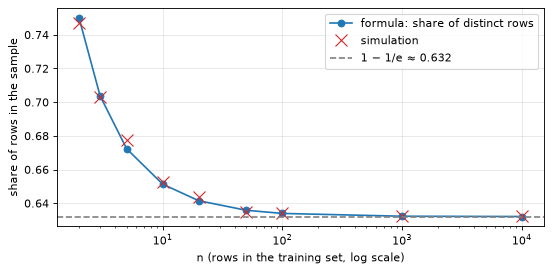

In [5]:
rng = np.random.default_rng(0)
n_values = np.array([2, 3, 5, 10, 20, 50, 100, 1000, 10000])
formula = 1 - (1 - 1 / n_values) ** n_values
simulated = np.array([np.mean([np.unique(rng.integers(0, n, n)).size / n for _ in range(500)]) for n in n_values])
print("    n   formula 1-(1-1/n)^n   simulated (500 samples)")
for n, f, s in zip(n_values, formula, simulated):
    print(f"{n:6d}   {f:.4f}               {s:.4f}")
print(f"limit 1 - 1/e = {1 - np.exp(-1):.4f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(n_values, formula, "o-", label="formula: share of distinct rows")
ax.semilogx(n_values, simulated, "x", ms=10, color="tab:red", label="simulation")
ax.axhline(1 - np.exp(-1), color="gray", ls="--", label="1 − 1/e ≈ 0.632")
ax.set_xlabel("n (rows in the training set, log scale)"); ax.set_ylabel("share of rows in the sample")
ax.legend(); plt.tight_layout(); plt.show()

Now the old notebook's classification data (3 classes, 10 features, 750 training rows) with two bagging set-ups:
the default (`max_samples` = all 750 rows) and `max_samples=100`.

In [6]:
X_clf, y_clf = make_classification(n_samples=1000, n_features=10, n_classes=3, n_informative=3, random_state=42)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_clf, y_clf, test_size=0.25, random_state=42)

bag_clf_all = BaggingClassifier(DecisionTreeClassifier(random_state=42), n_estimators=100,
                                oob_score=True, random_state=42).fit(Xc_tr, yc_tr)
bag_clf_100 = BaggingClassifier(DecisionTreeClassifier(random_state=42), n_estimators=100, max_samples=100,
                                oob_score=True, random_state=42).fit(Xc_tr, yc_tr)

n_c = len(yc_tr)
for name, bag, m in [("max_samples = 750 (default)", bag_clf_all, n_c), ("max_samples = 100", bag_clf_100, 100)]:
    draws = np.array([len(s) for s in bag.estimators_samples_])
    unique = np.array([np.unique(s).size for s in bag.estimators_samples_])
    print(f"{name}: draws per tree = {draws[0]},  distinct rows per tree = {unique.mean():.1f} on average "
          f"(formula {n_c * (1 - (1 - 1 / n_c) ** m):.1f})")
    print(f"    rows each tree never saw: {1 - unique.mean() / n_c:.1%}  (formula (1-1/750)^{m} = {(1 - 1 / n_c) ** m:.1%})")

max_samples = 750 (default): draws per tree = 750,  distinct rows per tree = 473.4 on average (formula 474.3)
    rows each tree never saw: 36.9%  (formula (1-1/750)^750 = 36.8%)
max_samples = 100: draws per tree = 100,  distinct rows per tree = 93.5 on average (formula 93.7)
    rows each tree never saw: 87.5%  (formula (1-1/750)^100 = 87.5%)


> **How to read this**
> * Formula and simulation agree for every n. The share of distinct rows falls from 0.75 (n = 2) towards
>   1 − 1/e = 0.632 and is already 0.634 at n = 100. "≈ 63.2 % in, ≈ 36.8 % out" describes **one tree's** bootstrap
>   sample when it has as many draws as there are rows.
> * `estimators_samples_` lists the **draws**: 750 per tree by default, but on average only 473.4 of them are distinct
>   rows (formula 474.3). The old notebook's "all samples are being used" counted draws.
> * With `max_samples=100` each tree makes 100 draws out of 750 rows: 93.5 distinct rows, and it never sees **87.5 %**
>   of the training set ((1 − 1/750)¹⁰⁰ = 0.875) — not 37 %.

## Lab 3 · One deep tree is unstable; the average is not

**Goal:** see the **high variance** of a deep decision tree: fitted to slightly different bootstrap samples of the
same 200 training rows it draws visibly different curves. Their average is smooth.

leaves per deep tree: 127 on average (200 training rows)
disagreement between trees (sd across the 200 trees): 0.222 on average over x, largest 0.579
RMSE against the true curve: single tree 0.337 (average over the 200 trees), average of 100 trees 0.238


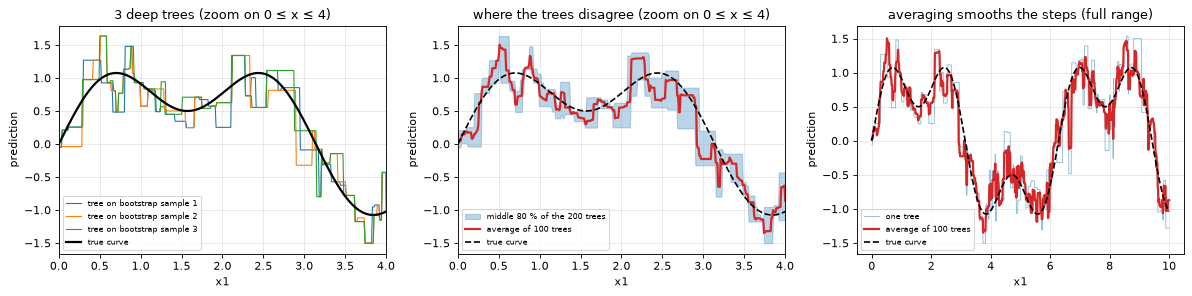

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(X_good, y_good, test_size=1 / 3, random_state=0)
x_grid = np.linspace(0, 10, 1000)[:, None]
f_grid = good_fit_truth(x_grid[:, 0])

rng = np.random.default_rng(0)
boot_trees = []
for b in range(200):                                       # 200 bootstrap samples, one deep tree each
    rows = rng.integers(0, len(y_tr), len(y_tr))
    boot_trees.append(DecisionTreeRegressor(random_state=0).fit(X_tr[rows], y_tr[rows]))
grid_preds = np.array([t.predict(x_grid) for t in boot_trees])
bag_curve = grid_preds[:100].mean(axis=0)                  # <- try changing this (number of trees averaged)

spread = grid_preds.std(axis=0)                            # how much the 200 trees disagree at each x
lo, hi = np.percentile(grid_preds, [10, 90], axis=0)
print(f"leaves per deep tree: {np.mean([t.get_n_leaves() for t in boot_trees]):.0f} on average (200 training rows)")
print(f"disagreement between trees (sd across the 200 trees): {spread.mean():.3f} on average over x, largest {spread.max():.3f}")
print(f"RMSE against the true curve: single tree {np.sqrt(np.mean((grid_preds - f_grid) ** 2)):.3f} (average over the 200 trees), "
      f"average of 100 trees {np.sqrt(np.mean((bag_curve - f_grid) ** 2)):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for b, color in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
    axes[0].plot(x_grid, grid_preds[b], color=color, lw=1, label=f"tree on bootstrap sample {b + 1}")
axes[0].plot(x_grid, f_grid, "k", lw=2, label="true curve")
axes[0].set_xlim(0, 4); axes[0].set_title("3 deep trees (zoom on 0 ≤ x ≤ 4)")
axes[1].fill_between(x_grid[:, 0], lo, hi, color="tab:blue", alpha=0.3, label="middle 80 % of the 200 trees")
axes[1].plot(x_grid, bag_curve, color="tab:red", lw=2, label="average of 100 trees")
axes[1].plot(x_grid, f_grid, "k", lw=1.5, ls="--", label="true curve")
axes[1].set_xlim(0, 4); axes[1].set_title("where the trees disagree (zoom on 0 ≤ x ≤ 4)")
axes[2].plot(x_grid, grid_preds[0], color="tab:blue", lw=0.8, alpha=0.5, label="one tree")
axes[2].plot(x_grid, bag_curve, color="tab:red", lw=2, label="average of 100 trees")
axes[2].plot(x_grid, f_grid, "k", lw=1.5, ls="--", label="true curve")
axes[2].set_title("averaging smooths the steps (full range)")
for ax in axes:
    ax.set_xlabel("x1"); ax.set_ylabel("prediction"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: three deep trees grown on three bootstrap samples of the *same* 200 rows. Each has about 127 leaves — close
>   to one leaf per distinct row — so each copies its own sample's noise, and the copies differ: the steps sit in
>   different places and at different heights.
> * Middle: the blue band holds the middle 80 % of 200 such trees. On average the trees disagree by 0.222 (standard
>   deviation), at some x by up to 0.579. That disagreement *is* "high variance".
> * Right: the average of 100 trees (red) is much smoother. Its RMSE against the true curve is 0.238, versus 0.337
>   for a single tree.
> * The average is still not the true curve. All bootstrap samples come from one dataset, so the noise *in that
>   dataset* is shared by every tree and cannot be averaged away (Lab 7 measures this with fresh datasets).

## Lab 4 · How the predictions are combined

**Goal:** confirm what scikit-learn's bagging does at prediction time:
* regression — the **plain average** of the trees' predictions;
* classification — the **average of the trees' `predict_proba`** ("soft voting") when the base model has
  `predict_proba`; otherwise each model casts one vote and the class shares are the vote fractions ("hard voting").

In [8]:
bag_reg = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, oob_score=True, random_state=0).fit(X_tr, y_tr)
P_te = per_tree_predictions(bag_reg, X_te)                 # 100 trees x 100 test rows
print("regression: max |mean of trees - bag.predict| =", np.abs(P_te.mean(axis=0) - bag_reg.predict(X_te)).max())

proba_trees = np.array([t.predict_proba(Xc_te[:, f]) for t, f in zip(bag_clf_all.estimators_, bag_clf_all.estimators_features_)])
print("classification: max |mean of trees' predict_proba - bag.predict_proba| =",
      np.abs(proba_trees.mean(axis=0) - bag_clf_all.predict_proba(Xc_te)).max())


def hard_vote(bag, X):
    votes = np.array([t.predict(X[:, f]) for t, f in zip(bag.estimators_, bag.estimators_features_)]).astype(int)
    return np.array([np.bincount(col, minlength=len(bag.classes_)) for col in votes.T]).argmax(axis=1)


for depth in [None, 3]:                                    # deep trees have pure leaves; shallow trees do not
    bag_d = BaggingClassifier(DecisionTreeClassifier(max_depth=depth), n_estimators=100, random_state=0).fit(Xc_tr, yc_tr)
    soft = bag_d.predict(Xc_te)
    hard = hard_vote(bag_d, Xc_te)
    print(f"max_depth={depth}: soft vote and hard vote disagree on {np.sum(soft != hard)} of {len(yc_te)} test rows; "
          f"accuracy soft {accuracy_score(yc_te, soft):.3f}, hard {accuracy_score(yc_te, hard):.3f}")

bag_svc = BaggingClassifier(SVC(), n_estimators=10, random_state=0).fit(Xc_tr, yc_tr)   # SVC() has no predict_proba
print("\nbase model without predict_proba -> class shares are vote fractions (multiples of 1/10):")
print(bag_svc.predict_proba(Xc_te[:4]))

regression: max |mean of trees - bag.predict| = 0.0
classification: max |mean of trees' predict_proba - bag.predict_proba| = 0.0


max_depth=None: soft vote and hard vote disagree on 0 of 250 test rows; accuracy soft 0.856, hard 0.856
max_depth=3: soft vote and hard vote disagree on 5 of 250 test rows; accuracy soft 0.764, hard 0.772

base model without predict_proba -> class shares are vote fractions (multiples of 1/10):
[[0.  0.  1. ]
 [0.  1.  0. ]
 [0.7 0.3 0. ]
 [0.  0.  1. ]]


> **How to read this**
> * Regression: the mean of the 100 trees' predictions equals `bag.predict` exactly (difference 0.0).
> * Classification: the mean of the trees' `predict_proba` equals `bag.predict_proba` exactly — `BaggingClassifier`
>   does **soft voting**.
> * Deep trees have pure leaves, so each tree's probabilities are 0 or 1 and soft voting equals hard voting
>   (0 disagreements). With shallow trees (`max_depth=3`) leaves are mixed and the two rules disagree on 5 of 250
>   rows; here hard voting happens to score a bit higher (0.772 vs 0.764) — soft voting is the default, not a law.
> * `SVC()` has no `predict_proba`, so the bag falls back to counting votes: class shares are multiples of 1/10
>   (e.g. 0.7 / 0.3 / 0).

## Lab 5 · The variance formula: $\rho\sigma^2 + (1-\rho)\sigma^2/B$

**Goal:** check the README's formula (section 4.3) by simulation. We create $B$ numbers that each have variance
$\sigma^2 = 1$ and pairwise correlation $\rho$ (think: $B$ trees' predictions at one point, over many possible training
sets), average them, and measure the variance of the average.

rho    B=1     B=10    B=100   floor rho*sigma^2   (simulated variance of the average)
0.0   0.992   0.100   0.010   0.000
0.2   0.986   0.281   0.207   0.200
0.5   0.985   0.547   0.505   0.500


0.8   0.982   0.806   0.787   0.800


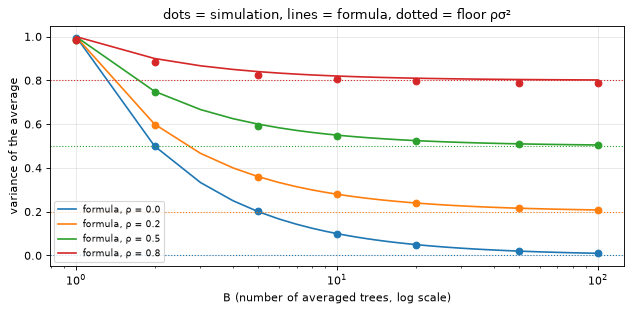

In [9]:
rng = np.random.default_rng(0)
n_rep, B_max = 20000, 100
B_values = np.array([1, 2, 5, 10, 20, 50, 100])
rho_values = [0.0, 0.2, 0.5, 0.8]                          # <- try changing this
fig, ax = plt.subplots(figsize=(8, 4))
print("rho    B=1     B=10    B=100   floor rho*sigma^2   (simulated variance of the average)")
for rho, color in zip(rho_values, ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    shared = rng.normal(size=(n_rep, 1))                   # the part all "trees" have in common
    own = rng.normal(size=(n_rep, B_max))                  # each tree's private part
    preds = np.sqrt(rho) * shared + np.sqrt(1 - rho) * own # variance 1, pairwise correlation rho
    sim = np.array([preds[:, :B].mean(axis=1).var() for B in B_values])
    B_line = np.arange(1, B_max + 1)
    ax.plot(B_line, rho + (1 - rho) / B_line, color=color, label=f"formula, ρ = {rho}")
    ax.plot(B_values, sim, "o", color=color)
    ax.axhline(rho, color=color, ls=":", lw=1)
    print(f"{rho:.1f}   {sim[0]:.3f}   {sim[3]:.3f}   {sim[6]:.3f}   {rho:.3f}")
ax.set_xscale("log"); ax.set_xlabel("B (number of averaged trees, log scale)"); ax.set_ylabel("variance of the average")
ax.set_title("dots = simulation, lines = formula, dotted = floor ρσ²"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * With ρ = 0 (independent trees) the variance of the average is σ²/B: 0.992 → 0.100 → 0.010 for B = 1, 10, 100.
> * With ρ > 0 the curve flattens onto the dotted floor ρσ²: for ρ = 0.5 the variance is 0.547 at B = 10 and 0.505 at
>   B = 100 — 90 extra trees bought almost nothing.
> * More trees only remove the $(1-\rho)\sigma^2/B$ part. To go lower, the trees must become **less correlated**
>   (smaller ρ) — that is what random forests add.

## Lab 6 · Out-of-bag (OOB) predictions, rebuilt by hand

**Goal:** fix two old mistakes. OOB rows exist **whenever `bootstrap=True`** (also with `max_samples` = all rows), and
OOB predictions **are aggregated** — over the trees that did *not* see the row. That is exactly how `oob_score_` is
computed. Also: what happens to a row that every tree saw?

In [10]:
n_tr = len(y_tr)
oob_sum, oob_count = np.zeros(n_tr), np.zeros(n_tr)
for tree, rows, feats in zip(bag_reg.estimators_, bag_reg.estimators_samples_, bag_reg.estimators_features_):
    oob = np.bincount(rows, minlength=n_tr) == 0           # rows this tree never drew
    oob_sum[oob] += tree.predict(X_tr[oob][:, feats])
    oob_count[oob] += 1
oob_pred = oob_sum / oob_count
print("max |our OOB prediction - sklearn oob_prediction_| =", np.abs(oob_pred - bag_reg.oob_prediction_).max())
print(f"our OOB R^2 = {r2_score(y_tr, oob_pred):.6f}   sklearn oob_score_ = {bag_reg.oob_score_:.6f}")
print(f"OOB trees per row: mean {oob_count.mean():.1f} (expected 100 x 0.368 = 36.8), min {oob_count.min():.0f}, max {oob_count.max():.0f}")

with warnings.catch_warnings(record=True) as caught:      # the warning IS the lesson here
    warnings.simplefilter("always")
    bag3 = BaggingRegressor(DecisionTreeRegressor(), n_estimators=3, oob_score=True, random_state=0).fit(X_tr, y_tr)
print("\nwith only 3 trees sklearn warns:", [str(w.message) for w in caught])
seen_by_all = np.all([np.bincount(r, minlength=n_tr) > 0 for r in bag3.estimators_samples_], axis=0)
print(f"rows seen by all 3 trees (no OOB tree): {seen_by_all.sum()} of {n_tr} ({seen_by_all.mean():.1%}; expected 0.632^3 = {0.632 ** 3:.1%})")
print("their oob_prediction_ values:", np.unique(bag3.oob_prediction_[seen_by_all]), "(sklearn fills in 0)")
print(f"oob_score_ including them = {bag3.oob_score_:.3f};  R^2 on the other rows only = "
      f"{r2_score(y_tr[~seen_by_all], bag3.oob_prediction_[~seen_by_all]):.3f}")

max |our OOB prediction - sklearn oob_prediction_| = 0.0
our OOB R^2 = 0.752117   sklearn oob_score_ = 0.752117
OOB trees per row: mean 36.6 (expected 100 x 0.368 = 36.8), min 24, max 53

with only 3 trees sklearn warns: ['Some inputs do not have OOB scores. This probably means too few estimators were used to compute any reliable oob estimates.']
rows seen by all 3 trees (no OOB tree): 54 of 200 (27.0%; expected 0.632^3 = 25.2%)
their oob_prediction_ values: [0.] (sklearn fills in 0)
oob_score_ including them = 0.458;  R^2 on the other rows only = 0.645


> **How to read this**
> * Rebuilding the OOB predictions by hand — for each row, the average of the trees that did not draw it — gives
>   sklearn's `oob_prediction_` exactly (difference 0.0) and the same OOB R² (0.752117). OOB predictions **are**
>   aggregated, here over 36.6 trees per row on average (min 24, max 53).
> * This was the default `max_samples` (all 200 rows): OOB rows exist whenever `bootstrap=True`.
> * With only 3 trees, 54 of 200 rows (27 %; expected 0.632³ ≈ 25 %) were drawn by all three and have **no** OOB
>   prediction. sklearn warns and fills them with 0, which drags `oob_score_` down to 0.458; on the other rows the
>   score is 0.645. Use enough trees: with 100 trees the chance is 0.632¹⁰⁰ ≈ 10⁻²⁰.

---
# Part B — Why bagging is useful

## Lab 7 · Variance goes down, bias stays: retraining on 50 fresh training sets

**Goal:** measure the README's central claim (section 4.4). We draw 50 brand-new training sets of 200 rows from the
good-fit generator, refit each model on each, and compare the 50 fitted curves with the true curve:

* **bias²** = how far the *average* curve (over the 50 fits) is from the truth,
* **variance** = how much the 50 curves spread around their own average,
* **noise** = $0.35^2 = 0.1225$, which no model can remove. Expected test MSE ≈ bias² + variance + noise.

model                bias^2   variance   bias^2+var+noise
one deep tree        0.0023   0.1236     0.2485
bagged deep trees    0.0011   0.0592     0.1827
one stump            0.4313   0.0073     0.5611
bagged stumps        0.4088   0.0119     0.5432


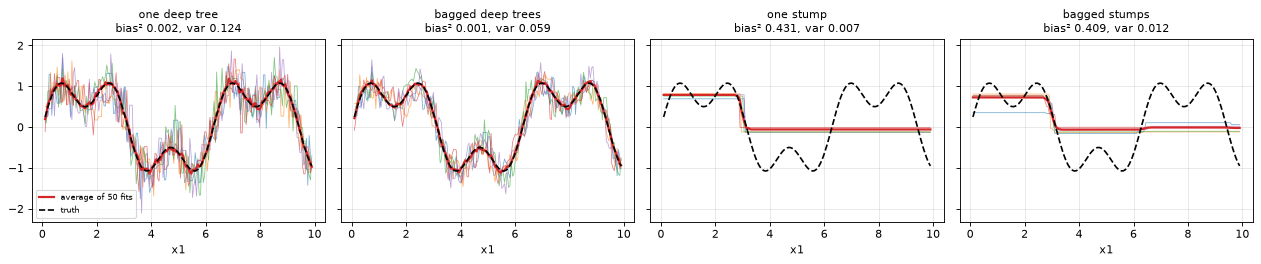

In [11]:
x_eval = np.linspace(0.1, 9.9, 200)[:, None]
f_eval = good_fit_truth(x_eval[:, 0])
B = 50
models = {"one deep tree": DecisionTreeRegressor(random_state=0),
          "bagged deep trees": BaggingRegressor(DecisionTreeRegressor(), n_estimators=B, random_state=0),
          "one stump": DecisionTreeRegressor(max_depth=1, random_state=0),
          "bagged stumps": BaggingRegressor(DecisionTreeRegressor(max_depth=1), n_estimators=B, random_state=0)}
n_sets = 50                                                # <- try changing this
curves = {name: np.empty((n_sets, len(x_eval))) for name in models}
tree_curves = np.empty((n_sets, B, len(x_eval)))           # the individual trees inside the bag
for s in range(n_sets):
    X_s, y_s = make_good_fit(seed=100 + s, n=200)
    for name, model in models.items():
        fitted = clone(model).fit(X_s, y_s)
        curves[name][s] = fitted.predict(x_eval)
        if name == "bagged deep trees":
            tree_curves[s] = per_tree_predictions(fitted, x_eval)

print("model                bias^2   variance   bias^2+var+noise")
decomposition = {}
for name, c in curves.items():
    bias2 = np.mean((c.mean(axis=0) - f_eval) ** 2)
    var = np.mean(c.var(axis=0))
    decomposition[name] = (bias2, var)
    print(f"{name:18s}   {bias2:.4f}   {var:.4f}     {bias2 + var + 0.35 ** 2:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, (name, c) in zip(axes, curves.items()):
    for s in range(5):
        ax.plot(x_eval, c[s], lw=0.7, alpha=0.6)
    ax.plot(x_eval, c.mean(axis=0), "tab:red", lw=2, label="average of 50 fits")
    ax.plot(x_eval, f_eval, "k--", lw=1.5, label="truth")
    ax.set_title(f"{name}\nbias² {decomposition[name][0]:.3f}, var {decomposition[name][1]:.3f}", fontsize=10)
    ax.set_xlabel("x1")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

Now the formula from Lab 5 on **real trees**: measure $\sigma^2$ (variance of one bagged tree over the 50 training
sets) and $\rho$ (correlation between two trees of the *same* bag over the 50 training sets), then compare.

In [12]:
sigma2_x = tree_curves.var(axis=0).mean(axis=0)            # per x: average variance of one tree
var_sum_x = tree_curves.sum(axis=1).var(axis=0)            # per x: variance of the sum of the B trees
cov_x = (var_sum_x - B * sigma2_x) / (B * (B - 1))         # per x: average covariance between two trees
rho_x = cov_x / sigma2_x
sigma2, rho = sigma2_x.mean(), rho_x.mean()
print(f"sigma^2 (one tree inside the bag) = {sigma2:.4f}   [one deep tree on all rows: {decomposition['one deep tree'][1]:.4f}]")
print(f"rho (two trees of the same bag)   = {rho:.3f}")
print(f"floor rho*sigma^2                 = {rho * sigma2:.4f}")
print(f"formula rho*s2 + (1-rho)*s2/B     = {np.mean(rho_x * sigma2_x + (1 - rho_x) * sigma2_x / B):.4f}")
print(f"measured variance of the bag      = {decomposition['bagged deep trees'][1]:.4f}")

sigma^2 (one tree inside the bag) = 0.1270   [one deep tree on all rows: 0.1236]
rho (two trees of the same bag)   = 0.454
floor rho*sigma^2                 = 0.0576
formula rho*s2 + (1-rho)*s2/B     = 0.0592
measured variance of the bag      = 0.0592


> **How to read this**
> * One deep tree: variance 0.124 — half of its expected test error (0.249). Its bias² is tiny (0.002): averaged over
>   many training sets, a deep tree is right.
> * Bagging 50 deep trees **halves the variance** (0.124 → 0.059) and bias² stays tiny (0.001). Expected test error
>   drops from 0.249 to 0.183; the noise 0.1225 is the floor nobody can beat.
> * With 50 training sets the bias² estimate itself carries an error of about variance/50 ≈ 0.002, so "0.002 vs
>   0.001" means "both ≈ 0" — not that bagging reduced bias.
> * Stumps are the opposite: bias² 0.431, variance 0.007. Bagging them changes almost nothing (0.409 and 0.012) —
>   there was no variance to remove. In the plots the stumps' average (red) stays a staircase far from the truth.
> * The formula on real trees: one tree inside the bag has σ² = 0.127 (close to a deep tree on all rows, 0.124), and
>   two trees of the same bag correlate ρ = 0.454 across training sets — they share the same data. Floor
>   ρσ² = 0.058; formula 0.0592; measured variance of the bag 0.0592. 50 trees already reach almost the floor.

## Lab 8 · More trees never over-fit: test and OOB error vs number of trees

**Goal:** watch the error as trees are added. We use the OOB error to *choose* the number of trees; the test curve is
drawn only to confirm (it is not used for any choice).

single deep tree test MSE: 0.2474
B =   1: OOB MSE 0.2517   test MSE 0.2328
B =   5: OOB MSE 0.1903   test MSE 0.1941
B =  10: OOB MSE 0.1776   test MSE 0.1916
B =  25: OOB MSE 0.1683   test MSE 0.1861
B =  50: OOB MSE 0.1585   test MSE 0.1853
B = 100: OOB MSE 0.1534   test MSE 0.1851
B = 300: OOB MSE 0.1527   test MSE 0.1840
chosen by OOB: B = 96 (first B whose OOB MSE is within 1 % of B = 300)


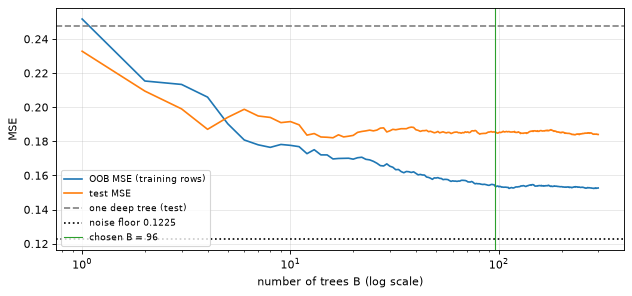

In [13]:
bag_300 = BaggingRegressor(DecisionTreeRegressor(), n_estimators=300, oob_score=True, random_state=0).fit(X_tr, y_tr)
P_te_300 = per_tree_predictions(bag_300, X_te)
P_tr_300 = per_tree_predictions(bag_300, X_tr)
oob_masks = np.array([np.bincount(r, minlength=n_tr) == 0 for r in bag_300.estimators_samples_])
B_axis = np.arange(1, 301)
test_mse = [mean_squared_error(y_te, P_te_300[:b].mean(axis=0)) for b in B_axis]
oob_mse = []
for b in B_axis:
    cnt = oob_masks[:b].sum(axis=0)
    has = cnt > 0                                          # rows with at least one OOB tree so far
    pred = (P_tr_300[:b] * oob_masks[:b]).sum(axis=0)[has] / cnt[has]
    oob_mse.append(mean_squared_error(y_tr[has], pred))
oob_mse = np.array(oob_mse)
single = DecisionTreeRegressor(random_state=0).fit(X_tr, y_tr)
single_mse = mean_squared_error(y_te, single.predict(X_te))
chosen_B = int(B_axis[np.argmax(oob_mse <= 1.01 * oob_mse[-1])])   # first B within 1 % of the 300-tree OOB error
print(f"single deep tree test MSE: {single_mse:.4f}")
for b in [1, 5, 10, 25, 50, 100, 300]:
    print(f"B = {b:3d}: OOB MSE {oob_mse[b - 1]:.4f}   test MSE {test_mse[b - 1]:.4f}")
print(f"chosen by OOB: B = {chosen_B} (first B whose OOB MSE is within 1 % of B = 300)")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(B_axis, oob_mse, label="OOB MSE (training rows)")
ax.plot(B_axis, test_mse, label="test MSE")
ax.axhline(single_mse, color="gray", ls="--", label="one deep tree (test)")
ax.axhline(0.35 ** 2, color="k", ls=":", label="noise floor 0.1225")
ax.axvline(chosen_B, color="tab:green", lw=1, label=f"chosen B = {chosen_B}")
ax.set_xscale("log"); ax.set_xlabel("number of trees B (log scale)"); ax.set_ylabel("MSE"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * Both curves fall quickly for the first 10–25 trees and then flatten; neither turns back up. **More trees never
>   over-fit** — they only bring the average closer to its limit (the floor of Lab 5).
> * The OOB MSE at B = 96 is within 1 % of its value at B = 300, so B ≈ 100 is chosen with no test data. On test, one
>   deep tree scores 0.247; the bag 0.185 at B = 100 and 0.184 at B = 300.
> * The OOB curve is jumpy for small B because each row has few OOB trees (at B = 1 only the ≈ 37 % of rows that tree
>   did not draw can be scored).
> * OOB (0.153) and test (0.185) are measured on different rows — 200 training rows vs 100 test rows — so they differ
>   by sampling noise; Lab 9 shows the same spread across CV folds.

## Lab 9 · OOB vs cross-validation vs a held-out test set

**Goal:** the OOB estimate is a free stand-in for cross-validation: one fit instead of five.

In [14]:
t0 = time.perf_counter()
bag_oob = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, oob_score=True, random_state=0).fit(X_tr, y_tr)
t_oob = time.perf_counter() - t0
oob_estimate = mean_squared_error(y_tr, bag_oob.oob_prediction_)

t0 = time.perf_counter()
cv_scores = cross_val_score(BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=0), X_tr, y_tr,
                            cv=KFold(5, shuffle=True, random_state=0), scoring="neg_mean_squared_error")
t_cv = time.perf_counter() - t0
test_estimate = mean_squared_error(y_te, bag_oob.predict(X_te))
print(f"OOB MSE         {oob_estimate:.4f}   ({t_oob:.2f} s: 1 fit of 100 trees)")
print(f"5-fold CV MSE   {-cv_scores.mean():.4f}   ({t_cv:.2f} s: 5 fits of 100 trees; fold scores {-cv_scores})")
print(f"test MSE        {test_estimate:.4f}   (100 rows never used for training)")

OOB MSE         0.1534   (0.06 s: 1 fit of 100 trees)
5-fold CV MSE   0.1637   (0.24 s: 5 fits of 100 trees; fold scores [0.127 0.196 0.17  0.162 0.163])
test MSE        0.1851   (100 rows never used for training)


> **How to read this**
> * Three estimates of the same error: OOB 0.153, 5-fold CV 0.164 (folds range 0.127–0.196), test 0.185. The gaps are
>   no bigger than the differences between CV folds, so they agree within their own noise.
> * OOB needed **one** fit, CV needed **five** (see the timings). That is the practical value of OOB: tuning without a
>   separate validation set and without refitting.
> * In principle both OOB and CV are slightly pessimistic for the final model (each OOB prediction uses only ≈ 37 % of
>   the trees; each CV model trains on 80 % of the rows). Here the 100 test rows simply happen to be harder.

## Lab 10 · Bagging vs pasting, and how many rows each tree gets (`max_samples`)

**Goal:** compare **bagging** (rows drawn *with* replacement, `bootstrap=True`) with **pasting** (rows drawn *without*
replacement, `bootstrap=False`) for several `max_samples`. Pasting has no OOB rows, so both are scored by 5-fold
cross-validation on the training set; only the winner is evaluated on the test set.

max_samples   distinct rows/tree (bagging | pasting)   CV MSE bagging   CV MSE pasting


   0.1         15.3 |  16                       0.1683           0.1758


   0.2         29.1 |  32                       0.1361           0.1436


   0.4         52.9 |  64                       0.1383           0.1418


   0.6         72.4 |  96                       0.1456           0.1595


   0.8         88.3 | 128                       0.1563           0.1825


   1.0        101.3 | 160                       0.1637           0.2119

best by CV: max_samples=0.2, bootstrap=True (CV MSE 0.1361)
its test MSE (used once): 0.1733
pasting with max_samples=1.0 vs ONE tree: max |prediction difference| = 2.886579864025407e-15


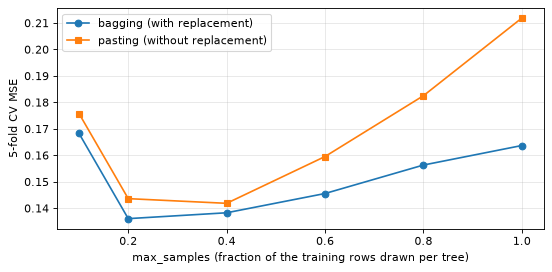

In [15]:
fractions = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
cv = KFold(5, shuffle=True, random_state=0)
results = {}
print("max_samples   distinct rows/tree (bagging | pasting)   CV MSE bagging   CV MSE pasting")
for frac in fractions:
    row = []
    for bootstrap in [True, False]:
        model = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, max_samples=frac, bootstrap=bootstrap, random_state=0)
        row.append(-cross_val_score(model, X_tr, y_tr, cv=cv, scoring="neg_mean_squared_error").mean())
        results[(frac, bootstrap)] = row[-1]
    m = int(frac * 160)                                    # 160 rows in each CV training fold
    print(f"   {frac:.1f}        {160 * (1 - (1 - 1 / 160) ** m):5.1f} | {m:3d}                       {row[0]:.4f}           {row[1]:.4f}")

best = min(results, key=results.get)
print(f"\nbest by CV: max_samples={best[0]}, bootstrap={best[1]} (CV MSE {results[best]:.4f})")
winner = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, max_samples=best[0], bootstrap=best[1], random_state=0).fit(X_tr, y_tr)
print(f"its test MSE (used once): {mean_squared_error(y_te, winner.predict(X_te)):.4f}")

paste_all = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, max_samples=1.0, bootstrap=False, random_state=0).fit(X_tr, y_tr)
print("pasting with max_samples=1.0 vs ONE tree: max |prediction difference| =",
      np.abs(paste_all.predict(X_te) - single.predict(X_te)).max())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(fractions, [results[(f, True)] for f in fractions], "o-", label="bagging (with replacement)")
ax.plot(fractions, [results[(f, False)] for f in fractions], "s-", label="pasting (without replacement)")
ax.set_xlabel("max_samples (fraction of the training rows drawn per tree)"); ax.set_ylabel("5-fold CV MSE"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * Bagging (blue) beats pasting (orange) at every `max_samples` here, but the **best** settings are close: bagging
>   0.136 (max_samples = 0.2) vs pasting 0.142 (max_samples = 0.4), about 4 %. "Bagging is much better than pasting"
>   is an overclaim.
> * The big gap at max_samples = 1.0 is not a fair fight: pasting *all* rows gives every tree the same data, so the
>   100 trees are identical and the "bag" equals one tree (max difference 3e-15). Averaging copies does nothing.
> * Smaller samples (fewer distinct rows per tree — see the table) make the trees more different from each other
>   (lower ρ) but each one worse (higher bias). CV finds the balance — here 20–40 % of the rows.
> * The test set was used once, for the CV winner: 0.173.

## Lab 11 · Each tree alone vs one full tree vs the bag (classification)

**Goal:** redo the old notebook's comparison correctly. For each of the 100 trees inside `bag_clf_all` we compute
per-class precision, recall and F1 on the test set and compare them with a single deep tree trained on all 750 rows.
This is a diagnostic (no model is chosen here).

max_samples = 750: accuracy single tree 0.828, mean tree 0.777, bag 0.848
    precision: single tree beats a tree on all 3 classes for  71 of 100 trees; per class it beats [90. 89. 90.] % of trees
    recall   : single tree beats a tree on all 3 classes for  57 of 100 trees; per class it beats [72. 89. 92.] % of trees
    F1       : single tree beats a tree on all 3 classes for  81 of 100 trees; per class it beats [85. 97. 98.] % of trees
max_samples = 100: accuracy single tree 0.828, mean tree 0.693, bag 0.828
    precision: single tree beats a tree on all 3 classes for  84 of 100 trees; per class it beats [ 87. 100.  96.] % of trees
    recall   : single tree beats a tree on all 3 classes for  76 of 100 trees; per class it beats [82. 97. 97.] % of trees
    F1       : single tree beats a tree on all 3 classes for  92 of 100 trees; per class it beats [ 92. 100. 100.] % of trees


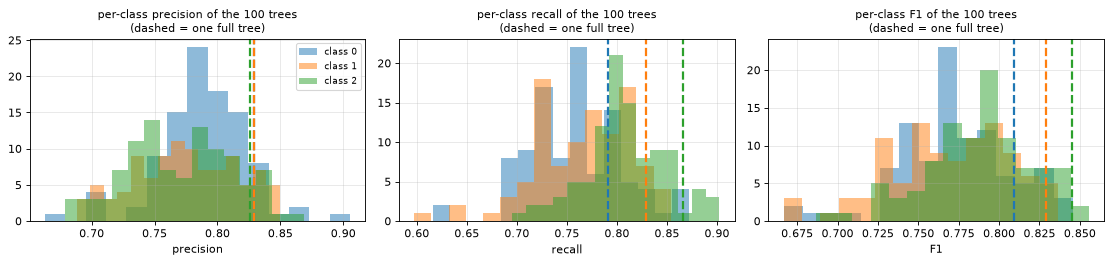

In [16]:
single_clf = DecisionTreeClassifier(random_state=42).fit(Xc_tr, yc_tr)
single_prf = np.array(precision_recall_fscore_support(yc_te, single_clf.predict(Xc_te))[:3])    # 3 metrics x 3 classes

for name, bag in [("max_samples = 750", bag_clf_all), ("max_samples = 100", bag_clf_100)]:
    tree_preds = per_tree_predictions(bag, Xc_te).astype(int)
    tree_prf = np.array([precision_recall_fscore_support(yc_te, p, zero_division=0)[:3] for p in tree_preds])  # 100 x 3 x 3
    beaten_all = (single_prf[None] > tree_prf).all(axis=2)          # single tree better on ALL 3 classes?
    print(f"{name}: accuracy single tree {accuracy_score(yc_te, single_clf.predict(Xc_te)):.3f}, "
          f"mean tree {np.mean([accuracy_score(yc_te, p) for p in tree_preds]):.3f}, bag {accuracy_score(yc_te, bag.predict(Xc_te)):.3f}")
    for k, metric in enumerate(["precision", "recall", "F1"]):
        print(f"    {metric:9s}: single tree beats a tree on all 3 classes for {beaten_all[:, k].sum():3d} of 100 trees; "
              f"per class it beats {(single_prf[k] > tree_prf[:, k]).mean(axis=0) * 100} % of trees")
    if bag is bag_clf_all:
        prf_all = tree_prf

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for k, (ax, metric) in enumerate(zip(axes, ["precision", "recall", "F1"])):
    for c, color in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
        ax.hist(prf_all[:, k, c], bins=15, alpha=0.5, color=color, label=f"class {c}")
        ax.axvline(single_prf[k, c], color=color, ls="--", lw=2)
    ax.set_title(f"per-class {metric} of the 100 trees\n(dashed = one full tree)", fontsize=10); ax.set_xlabel(metric)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

> **How to read this**
> * One full tree (accuracy 0.828) beats the **average** tree inside the bag (0.777 with 750 draws, 0.693 with 100) —
>   each bagged tree saw fewer distinct rows. Yet the bag (0.848 with 750 draws) beats the full tree: the gain comes
>   from **averaging**, not from better trees.
> * Reading the old `Counter((single > per_tree).all(axis=1))` correctly: it counts the trees that the single tree
>   beats on **all three classes at once**. With 100 draws per tree that is 84 of 100 for precision, so the other 16
>   trees tie or win on **at least one class** — not "16 trees were as precise or more precise".
> * Per class the single tree beats most trees (for precision with 750 draws: 90 %, 89 %, 90 %). In the histograms
>   (recall now plotted for every class — the old plot drew class 1 twice) most trees sit left of the dashed lines.

## Lab 12 · How correlated are the trees' mistakes?

**Goal:** keep the old notebook's heat-maps and its "> 0.9" check, but read them correctly. For each pair of trees we
correlate their **errors on the test rows** (classification: 1 = wrong, 0 = right; regression: residual). Values well
below 1 mean the trees make partly *different* mistakes — the diversity bagging relies on.

classification (misclassification indicators): off-diagonal correlation mean 0.40, min 0.18, max 0.67; pairs above 0.9: 0
regression (residuals, good fit): off-diagonal correlation mean 0.75, min 0.54, max 0.90; pairs above 0.9: 0

regression trees' test MSE ranges from 0.186 to 0.305
most similar MSE pair: trees 59 and 94 (MSE 0.2513 vs 0.2513) -> error correlation 0.77
most correlated pair : trees 66 and 90 (correlation 0.90) -> MSE 0.2464 vs 0.2354


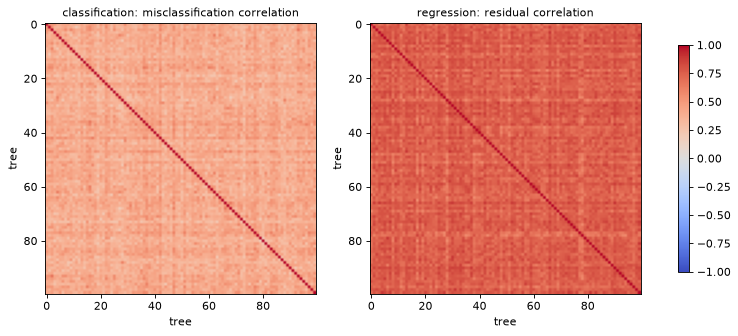

In [17]:
def high_pairs(corr, threshold=0.9):
    i, j = np.where(np.abs(corr) > threshold)
    return [(a, b) for a, b in zip(i, j) if a < b]


wrong = (per_tree_predictions(bag_clf_all, Xc_te).astype(int) != yc_te).astype(int)   # 100 trees x 250 rows
corr_clf = np.corrcoef(wrong)
resid = P_te - y_te                                                                   # bag_reg from Lab 4
corr_reg = np.corrcoef(resid)
off = ~np.eye(100, dtype=bool)
for name, corr in [("classification (misclassification indicators)", corr_clf), ("regression (residuals, good fit)", corr_reg)]:
    print(f"{name}: off-diagonal correlation mean {corr[off].mean():.2f}, min {corr[off].min():.2f}, max {corr[off].max():.2f}; "
          f"pairs above 0.9: {len(high_pairs(corr))}")

tree_mse = (resid ** 2).mean(axis=1)
print(f"\nregression trees' test MSE ranges from {tree_mse.min():.3f} to {tree_mse.max():.3f}")
d_mse = np.abs(tree_mse[:, None] - tree_mse[None, :]) + np.eye(100) * 1e9
a, b = np.unravel_index(np.argmin(d_mse), d_mse.shape)
print(f"most similar MSE pair: trees {a} and {b} (MSE {tree_mse[a]:.4f} vs {tree_mse[b]:.4f}) -> error correlation {corr_reg[a, b]:.2f}")
c_tmp = np.where(off, corr_reg, -1)
a, b = np.unravel_index(np.argmax(c_tmp), c_tmp.shape)
print(f"most correlated pair : trees {a} and {b} (correlation {corr_reg[a, b]:.2f}) -> MSE {tree_mse[a]:.4f} vs {tree_mse[b]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, corr, title in [(axes[0], corr_clf, "classification: misclassification correlation"),
                        (axes[1], corr_reg, "regression: residual correlation")]:
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("tree"); ax.set_ylabel("tree"); ax.grid(False)
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

> **How to read this**
> * No pair of trees exceeds 0.9 in either problem, so the old "> 0.9" check passes — but that check only rules out
>   near-duplicate trees. It does **not** mean the errors are uncorrelated.
> * Classification: mistakes correlate 0.40 on average (0.18–0.67). Regression on the good-fit data: residuals
>   correlate 0.75 on average (0.54–0.90) — the trees make largely the *same* errors because they share the training
>   rows and their noise. Both heat-maps are warm everywhere, not white.
> * Correlation and MSE answer different questions: trees 59 and 94 have the same MSE (0.2513) and error correlation
>   0.77; the most correlated pair (0.90) has MSEs 0.246 and 0.235. Similar MSE does not imply correlated errors, nor
>   the reverse.
> * This is correlation of errors **across test rows, for one training set**. The ρ in the variance formula is
>   correlation **across training sets, at a fixed x** (Lab 7: 0.45). Both say "far from independent", but they are
>   different numbers.

## Lab 13 · 100 rows per tree vs all 750 rows, chosen by OOB (and the OOB class shares)

**Goal:** explain the old notebook's "Hmm… strange" result and choose between the two set-ups **without** the test set.

In [18]:
for name, bag, m in [("max_samples = 750", bag_clf_all, 750), ("max_samples = 100", bag_clf_100, 100)]:
    tree_acc = np.mean([accuracy_score(yc_te, p) for p in per_tree_predictions(bag, Xc_te).astype(int)])
    print(f"{name}: distinct rows/tree {np.mean([np.unique(s).size for s in bag.estimators_samples_]):.0f}, "
          f"OOB accuracy {bag.oob_score_:.3f}")
choice = max([bag_clf_all, bag_clf_100], key=lambda b: b.oob_score_)
print("chosen by OOB:", "max_samples = 750" if choice is bag_clf_all else "max_samples = 100")
print(f"confirmation on test (used once): 750 -> {accuracy_score(yc_te, bag_clf_all.predict(Xc_te)):.3f}, "
      f"100 -> {accuracy_score(yc_te, bag_clf_100.predict(Xc_te)):.3f}")

oob_df = bag_clf_100.oob_decision_function_
print("\noob_decision_function_ (first 4 rows; one row per training row, one column per class):\n", oob_df[:4])
print("every row sums to 1:", np.allclose(oob_df.sum(axis=1), 1))
print("accuracy of its arg-max =", accuracy_score(yc_tr, oob_df.argmax(axis=1)), " oob_score_ =", bag_clf_100.oob_score_)

max_samples = 750: distinct rows/tree 473, OOB accuracy 0.849
max_samples = 100: distinct rows/tree 94, OOB accuracy 0.817
chosen by OOB: max_samples = 750
confirmation on test (used once): 750 -> 0.848, 100 -> 0.828

oob_decision_function_ (first 4 rows; one row per training row, one column per class):
 [[0.149 0.092 0.759]
 [0.94  0.012 0.048]
 [0.056 0.878 0.067]
 [0.291 0.267 0.442]]
every row sums to 1: True
accuracy of its arg-max = 0.8173333333333334  oob_score_ = 0.8173333333333334


> **How to read this**
> * The old "Hmm… strange" (the 750-draw bag beating the 100-draw bag) is expected: its trees see ≈ 473 distinct rows
>   each instead of ≈ 94, so every tree is much better (lower bias), and averaging cannot undo bias.
> * OOB accuracy picks the same winner without the test set: 0.849 vs 0.817. The test set, used once to confirm,
>   agrees: 0.848 vs 0.828.
> * `oob_decision_function_` has one row per **training** row: the average class probabilities of the trees that did
>   not see that row. Rows sum to 1, and their most probable class reproduces `oob_score_` exactly (0.8173).

## Lab 14 · Random subspaces vs random patches (done right)

**Goal:** sample **features** as well as rows. Friedman #1 data: 10 features, only the first 5 matter.

| Name | rows per tree | features per tree |
|---|---|---|
| bagging | bootstrap (with replacement) | all |
| random subspaces | **all rows** (`bootstrap=False, max_samples=1.0`) | a random subset (`max_features`) |
| random patches | bootstrap | a random subset |
| the old notebook's "subspaces" | 60 % bootstrap | all 10 drawn **with replacement** (`bootstrap_features=True`) — really random patches |

Configurations are compared by 5-fold CV on the training set; only the winner and plain bagging see the test set.

In [19]:
X_fr, y_fr = make_friedman1(n_samples=1000, n_features=10, noise=1.0, random_state=0)
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(X_fr, y_fr, test_size=0.25, random_state=0)
configs = {
    "bagging": dict(bootstrap=True),
    "random subspaces (50% features)": dict(bootstrap=False, max_samples=1.0, max_features=0.5),
    "random patches (50% features)": dict(bootstrap=True, max_features=0.5),
    "random patches (80% features)": dict(bootstrap=True, max_features=0.8),
    "old 'subspaces' = patches, features w/ repl.": dict(bootstrap=True, max_samples=0.6, bootstrap_features=True),
}
cv_mse, fitted = {}, {}
for name, params in configs.items():
    model = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=0, **params)
    cv_mse[name] = -cross_val_score(model, Xf_tr, yf_tr, cv=KFold(5, shuffle=True, random_state=0), scoring="neg_mean_squared_error").mean()
    fitted[name] = clone(model).fit(Xf_tr, yf_tr)
    feats0 = fitted[name].estimators_features_[0]
    n_unique = np.mean([np.unique(f).size for f in fitted[name].estimators_features_])
    print(f"{name:45s} CV MSE {cv_mse[name]:.3f}   tree 0 features {np.sort(feats0)}  distinct features/tree {n_unique:.1f}")
best_name = min(cv_mse, key=cv_mse.get)
print(f"\nbest by CV: {best_name}; test MSE {mean_squared_error(yf_te, fitted[best_name].predict(Xf_te)):.3f} "
      f"(plain bagging: {mean_squared_error(yf_te, fitted['bagging'].predict(Xf_te)):.3f})")

bagging                                       CV MSE 4.332   tree 0 features [0 1 2 3 4 5 6 7 8 9]  distinct features/tree 10.0


random subspaces (50% features)               CV MSE 10.056   tree 0 features [1 4 5 6 9]  distinct features/tree 5.0


random patches (50% features)                 CV MSE 9.771   tree 0 features [1 4 5 6 9]  distinct features/tree 5.0


random patches (80% features)                 CV MSE 4.956   tree 0 features [0 1 4 5 6 7 8 9]  distinct features/tree 8.0


old 'subspaces' = patches, features w/ repl.  CV MSE 6.913   tree 0 features [0 0 2 2 3 3 6 7 9 9]  distinct features/tree 6.5

best by CV: bagging; test MSE 3.863 (plain bagging: 3.863)


> **How to read this**
> * Done right: random **subspaces** keep all rows and draw features without replacement (tree 0 got features
>   1, 4, 5, 6, 9); random **patches** draw both.
> * The old notebook's "subspaces" model was really random patches with features drawn **with** replacement: tree 0
>   got `[0 0 2 2 3 3 6 7 9 9]`, only 6.5 distinct features per tree on average — duplicates add nothing.
> * On this data plain bagging wins (CV MSE 4.33). Half the features per tree is much worse (≈ 10): a tree that never
>   got feature 3, the strongest, cannot use it **anywhere**. With 80 % of the features (4.96) it is closer but still
>   worse. Per-tree feature sampling is blunt when only a few features matter; random forests sample features **per
>   split**, which is far gentler.
> * The CV winner (plain bagging) scores 3.86 on the test set.

## Lab 15 · Feature importance of a bag: average the trees' importances

**Goal:** finish the old notebook's unfinished section. `BaggingRegressor` has no `feature_importances_` (the base model
could be anything), but when the base model is a tree we can average the trees' importances — mapping each tree's
features back to the original columns via `estimators_features_` (needed when features are subsampled). We compare
with **permutation importance** on the test set (how much the test error grows when one column is shuffled).

BaggingRegressor has feature_importances_? False


averaged tree importances (bagging)      : [0.2   0.207 0.05  0.394 0.086 0.012 0.012 0.014 0.014 0.012]  sum = 1.0
averaged tree importances (random patches): [0.16  0.146 0.101 0.205 0.107 0.058 0.055 0.049 0.058 0.062]
permutation importance on test (bagging)  : [ 0.367  0.415  0.05   0.646  0.118  0.001  0.001  0.002 -0.002  0.001]


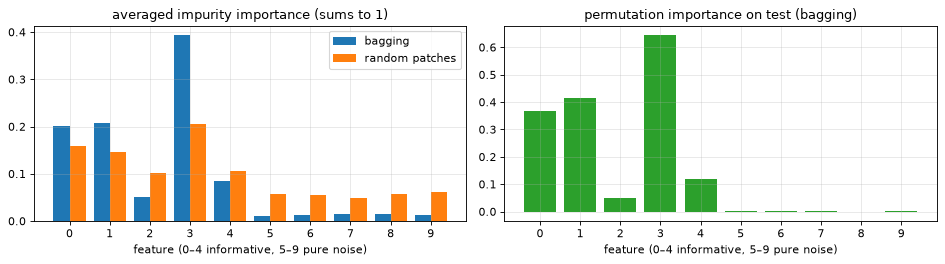

In [20]:
def averaged_importances(bag, n_features):
    """Mean of the trees' feature_importances_, mapped back to the original column numbers."""
    total = np.zeros(n_features)
    for tree, feats in zip(bag.estimators_, bag.estimators_features_):
        np.add.at(total, feats, tree.feature_importances_)   # add.at also handles repeated feature indices
    return total / len(bag.estimators_)


print("BaggingRegressor has feature_importances_?", hasattr(fitted["bagging"], "feature_importances_"))
imp_bag = averaged_importances(fitted["bagging"], 10)
imp_patch = averaged_importances(fitted["random patches (50% features)"], 10)
perm = permutation_importance(fitted["bagging"], Xf_te, yf_te, n_repeats=10, random_state=0).importances_mean
print("averaged tree importances (bagging)      :", imp_bag, " sum =", round(imp_bag.sum(), 6))
print("averaged tree importances (random patches):", imp_patch)
print("permutation importance on test (bagging)  :", perm)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
idx = np.arange(10)
axes[0].bar(idx - 0.2, imp_bag, width=0.4, label="bagging")
axes[0].bar(idx + 0.2, imp_patch, width=0.4, label="random patches")
axes[0].set_title("averaged impurity importance (sums to 1)")
axes[1].bar(idx, perm, color="tab:green"); axes[1].set_title("permutation importance on test (bagging)")
for ax in axes:
    ax.set_xticks(idx); ax.set_xlabel("feature (0–4 informative, 5–9 pure noise)")
axes[0].legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * `BaggingRegressor` has no `feature_importances_`; averaging the trees' impurity importances gives one (it sums
>   to 1).
> * Both methods put the informative features 0–4 on top and give the noise features 5–9 almost nothing (≈ 0.012
>   averaged importance, ≈ 0.00 permutation). Feature 3 (coefficient 10 in Friedman #1) is the strongest.
> * With random patches (5 features per tree) importance spreads more evenly (noise features ≈ 0.05–0.06): a tree
>   without the good features must split on whatever it got. Mapping each tree's columns back with
>   `estimators_features_` (and `np.add.at` for repeated columns) is essential — otherwise the numbers land on the
>   wrong features.
> * Impurity importance is measured on training data and can favour features with many possible split points;
>   permutation importance on held-out data is the safer cross-check.

---
# Part C — Where bagging fails

## Lab 16 · Stable or high-bias base models: nothing to gain

**Goal:** bagging only reduces *variance*. A **linear regression** barely changes between bootstrap samples (stable),
and a **stump** is wrong in the same way on every sample (high bias). Bagging either changes nothing.

linear regression: test MSE 0.8455; bagged (100): 0.8452; max |prediction difference| on the grid 0.0406
slopes of the 100 bootstrap fits: -0.045 .. 0.035 (full-data slope -0.015)
stump: test MSE 0.6927; bagged stumps: 0.6554; bagged deep trees: 0.1851
bias^2 / variance from Lab 7: {'one stump': (np.float64(0.4313), np.float64(0.0073)), 'bagged stumps': (np.float64(0.4088), np.float64(0.0119))}


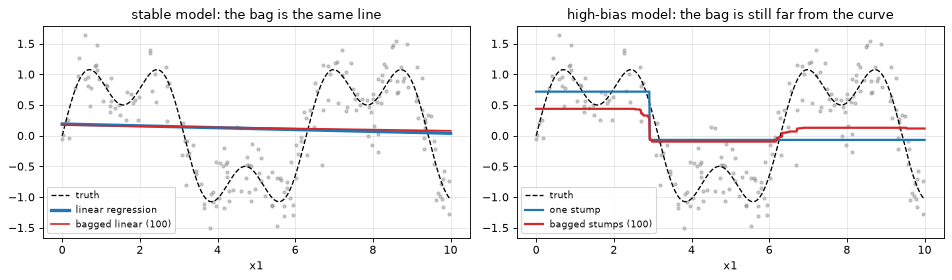

In [21]:
lin = LinearRegression().fit(X_tr, y_tr)
bag_lin = BaggingRegressor(LinearRegression(), n_estimators=100, random_state=0).fit(X_tr, y_tr)
slopes = np.array([m.coef_[0] for m in bag_lin.estimators_])
print(f"linear regression: test MSE {mean_squared_error(y_te, lin.predict(X_te)):.4f}; "
      f"bagged (100): {mean_squared_error(y_te, bag_lin.predict(X_te)):.4f}; "
      f"max |prediction difference| on the grid {np.abs(lin.predict(x_grid) - bag_lin.predict(x_grid)).max():.4f}")
print(f"slopes of the 100 bootstrap fits: {slopes.min():.3f} .. {slopes.max():.3f} (full-data slope {lin.coef_[0]:.3f})")

stump = DecisionTreeRegressor(max_depth=1).fit(X_tr, y_tr)
bag_stump = BaggingRegressor(DecisionTreeRegressor(max_depth=1), n_estimators=100, random_state=0).fit(X_tr, y_tr)
print(f"stump: test MSE {mean_squared_error(y_te, stump.predict(X_te)):.4f}; bagged stumps: {mean_squared_error(y_te, bag_stump.predict(X_te)):.4f}; "
      f"bagged deep trees: {mean_squared_error(y_te, bag_reg.predict(X_te)):.4f}")
print("bias^2 / variance from Lab 7:", {k: tuple(round(v, 4) for v in decomposition[k]) for k in ["one stump", "bagged stumps"]})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax in axes:
    ax.scatter(X_tr[:, 0], y_tr, s=8, alpha=0.4, color="gray")
    ax.plot(x_grid, f_grid, "k--", lw=1.2, label="truth")
axes[0].plot(x_grid, lin.predict(x_grid), lw=3, label="linear regression")
axes[0].plot(x_grid, bag_lin.predict(x_grid), lw=1.5, color="tab:red", label="bagged linear (100)")
axes[0].set_title("stable model: the bag is the same line")
axes[1].plot(x_grid, stump.predict(x_grid), lw=2, label="one stump")
axes[1].plot(x_grid, bag_stump.predict(x_grid), lw=2, color="tab:red", label="bagged stumps (100)")
axes[1].set_title("high-bias model: the bag is still far from the curve")
for ax in axes:
    ax.set_xlabel("x1"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * Linear regression is **stable**: the 100 bootstrap slopes only range from −0.045 to 0.035, and the bagged line
>   differs from the plain one by at most 0.041. Test MSE 0.8455 vs 0.8452 — the same. A straight line through a
>   wiggly curve is wrong because of **bias**, and bagging does not touch bias.
> * A stump is **biased**: one step cannot follow the waves. Bagged stumps (0.655) barely beat one stump (0.693) and
>   stay far behind bagged deep trees (0.185). Lab 7 showed why: bias² 0.431 → 0.409, and the variance was tiny to
>   begin with (0.007).
> * Rule: bag models that are **low-bias and unstable** (deep trees). For stable or high-bias models, bagging is
>   wasted compute; use a more flexible model or boosting, which attacks bias.

## Lab 17 · Extrapolation: the bad-fit dataset

**Goal:** train on $x < 6$, predict $6 \le x \le 10$. A tree predicts the average of a leaf, and every leaf holds
training rows — so outside the training range a tree (and any average of trees) is **flat**.

110 training rows (x < 6), 90 test rows (x >= 6)
one deep tree        test MSE   6.524   predictions at x = 6, 8, 10: [5.183 5.183 5.183]
bagged trees (100)   test MSE   4.727   predictions at x = 6, 8, 10: [5.603 5.603 5.603]


linear regression    test MSE   0.300   predictions at x = 6, 8, 10: [5.723 7.291 8.86 ]
bagged linear (100)  test MSE   0.301   predictions at x = 6, 8, 10: [5.714 7.283 8.852]
largest training y = 6.516; true value at x = 10 is 9.0


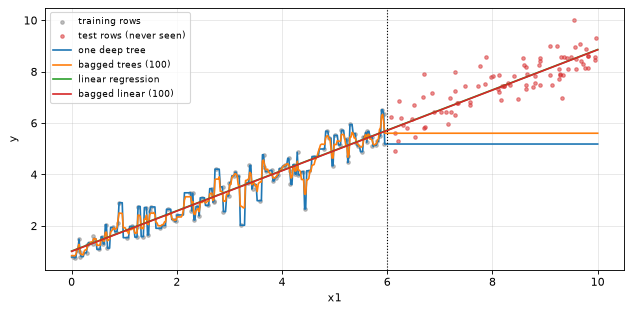

In [22]:
Xb_tr, yb_tr = X_bad[X_bad[:, 0] < 6], y_bad[X_bad[:, 0] < 6]
Xb_te, yb_te = X_bad[X_bad[:, 0] >= 6], y_bad[X_bad[:, 0] >= 6]
bad_models = {"one deep tree": DecisionTreeRegressor(random_state=0),
              "bagged trees (100)": BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=0),
              "linear regression": LinearRegression(),
              "bagged linear (100)": BaggingRegressor(LinearRegression(), n_estimators=100, random_state=0)}
print(f"{len(yb_tr)} training rows (x < 6), {len(yb_te)} test rows (x >= 6)")
xb_grid = np.linspace(0, 10, 500)[:, None]
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(Xb_tr[:, 0], yb_tr, s=10, alpha=0.5, color="gray", label="training rows")
ax.scatter(Xb_te[:, 0], yb_te, s=10, alpha=0.5, color="tab:red", label="test rows (never seen)")
for name, model in bad_models.items():
    model.fit(Xb_tr, yb_tr)
    print(f"{name:20s} test MSE {mean_squared_error(yb_te, model.predict(Xb_te)):7.3f}   "
          f"predictions at x = 6, 8, 10: {model.predict(np.array([[6.0], [8.0], [10.0]]))}")
    ax.plot(xb_grid, model.predict(xb_grid), lw=1.5, label=name)
print(f"largest training y = {yb_tr.max():.3f}; true value at x = 10 is {bad_fit_truth(10.0):.1f}")
ax.axvline(6, color="k", lw=1, ls=":"); ax.set_xlabel("x1"); ax.set_ylabel("y"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * Inside the training range (x < 6) the bagged trees follow the line. Beyond it every tree predicts the mean of its
>   right-most leaf, so the bag is **flat**: 5.603 at x = 6, 8 and 10, while the truth climbs to 9.0 at x = 10 (the
>   largest training y is only 6.516).
> * Test MSE on x ≥ 6: one tree 6.52, bagged trees 4.73 (averaging softens the edge, the flat line remains), linear
>   regression 0.300.
> * Bagging the linear model changes nothing (0.301 vs 0.300), as in Lab 16.
> * Fix: use a model that can extrapolate (a linear model, or a linear trend plus trees on what is left over), or do
>   not predict outside the range you trained on.

## Lab 18 · Small data

**Goal:** test the old notebook's warning that bagging helps less on a **too-small** dataset, and find the real reason.
For several training-set sizes $n$ we fit a deep tree and a bag of 50 trees on 30 fresh training sets and measure
bias² and variance against the true curve (as in Lab 7).

    n   tree bias^2  tree var   bag bias^2  bag var   bag/tree error   P(row in two given samples)


   10   0.0984       0.3471     0.1607      0.2110    0.83             0.424


   20   0.0225       0.2395     0.0540      0.1470    0.77             0.412


   50   0.0058       0.1470     0.0077      0.0783    0.56             0.404


  100   0.0047       0.1281     0.0025      0.0621    0.49             0.402


  200   0.0041       0.1212     0.0019      0.0572    0.47             0.401


  500   0.0036       0.1213     0.0017      0.0587    0.48             0.400


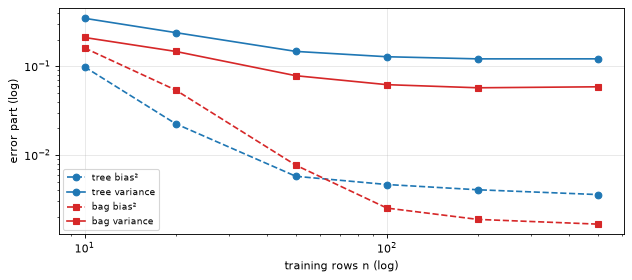

In [23]:
n_sizes = [10, 20, 50, 100, 200, 500]
print("    n   tree bias^2  tree var   bag bias^2  bag var   bag/tree error   P(row in two given samples)")
small_rows = []
for n in n_sizes:
    c_tree, c_bag = np.empty((30, len(x_eval))), np.empty((30, len(x_eval)))
    for s in range(30):
        X_s, y_s = make_good_fit(seed=1000 + s, n=n)
        c_tree[s] = DecisionTreeRegressor(random_state=0).fit(X_s, y_s).predict(x_eval)
        c_bag[s] = BaggingRegressor(DecisionTreeRegressor(), n_estimators=50, random_state=s).fit(X_s, y_s).predict(x_eval)
    bt, vt = np.mean((c_tree.mean(0) - f_eval) ** 2), np.mean(c_tree.var(0))
    bb, vb = np.mean((c_bag.mean(0) - f_eval) ** 2), np.mean(c_bag.var(0))
    overlap = (1 - (1 - 1 / n) ** n) ** 2
    small_rows.append((n, bt, vt, bb, vb))
    print(f"{n:5d}   {bt:.4f}       {vt:.4f}     {bb:.4f}      {vb:.4f}    {(bb + vb) / (bt + vt):.2f}             {overlap:.3f}")

small_rows = np.array(small_rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(small_rows[:, 0], small_rows[:, 1], "o--", color="tab:blue", label="tree bias²")
ax.plot(small_rows[:, 0], small_rows[:, 2], "o-", color="tab:blue", label="tree variance")
ax.plot(small_rows[:, 0], small_rows[:, 3], "s--", color="tab:red", label="bag bias²")
ax.plot(small_rows[:, 0], small_rows[:, 4], "s-", color="tab:red", label="bag variance")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("training rows n (log)"); ax.set_ylabel("error part (log)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

> **How to read this**
> * The *relative* gain of bagging shrinks on small data: the bag's error (bias² + variance) is 0.83 of the single
>   tree's at n = 10 and 0.77 at n = 20, but 0.47–0.49 for n ≥ 100.
> * Why: each tree sees only ≈ 63 % of the rows — at n = 10 about 6.5 distinct rows, too few to follow the curve. So
>   the bag's **bias rises** (tree 0.098 → bag 0.161 at n = 10; 0.023 → 0.054 at n = 20) and eats much of the
>   variance saving. For n ≥ 100 bias is negligible on both sides (the values ≈ 0.002–0.005 are mostly measurement
>   noise, about variance/30) and the variance is roughly halved.
> * The old explanation — small data makes bootstrap samples "highly overlapping" — does not hold: the chance that a
>   row is in two given bootstrap samples is ≈ 0.40 for every n (0.424 at n = 10, 0.400 at n = 500). The problem is
>   too little data per tree, not extra overlap.

## Lab 19 · The price: time, memory and interpretability

**Goal:** a bag of $B$ trees costs about $B$ times one tree to train, store and query, and there is no single tree to read.

    B   fit time (s)   predict 100k rows (s)   total tree nodes
    1        0.001          0.001                   255
   10        0.005          0.008                  2556


  100        0.049          0.074                 25258


  500        0.224          0.370                126058


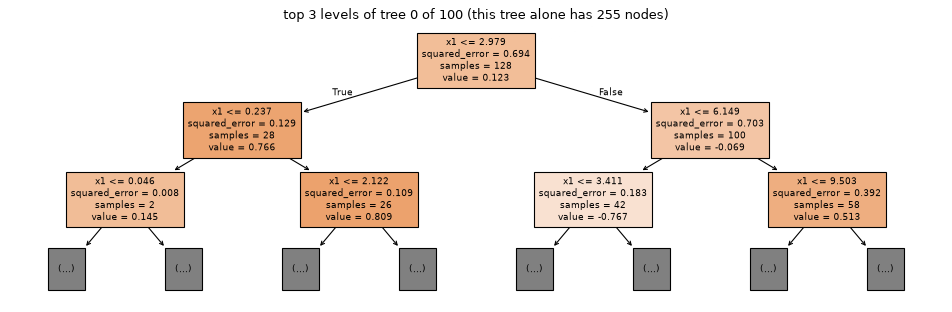

In [24]:
x_big = np.linspace(0, 10, 100_000)[:, None]
print("    B   fit time (s)   predict 100k rows (s)   total tree nodes")
for B_ in [1, 10, 100, 500]:
    t0 = time.perf_counter()
    m = BaggingRegressor(DecisionTreeRegressor(), n_estimators=B_, random_state=0).fit(X_tr, y_tr)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); m.predict(x_big); t_pred = time.perf_counter() - t0
    print(f"{B_:5d}   {t_fit:10.3f}     {t_pred:10.3f}              {sum(t.tree_.node_count for t in m.estimators_):8d}")

fig, ax = plt.subplots(figsize=(12, 4))
plot_tree(bag_reg.estimators_[0], max_depth=2, filled=True, ax=ax, fontsize=8, feature_names=["x1"])
ax.set_title(f"top 3 levels of tree 0 of 100 (this tree alone has {bag_reg.estimators_[0].tree_.node_count} nodes)")
plt.tight_layout(); plt.show()

> **How to read this**
> * Fit time, prediction time and stored nodes grow roughly in proportion to B: one tree has 255 nodes, 500 trees
>   126 058. (Timings differ from run to run; the trend does not.)
> * The picture is the top of **one** of the 100 trees (255 nodes in total). One tree's rules can be read; 100 averaged
>   trees cannot — bagging trades interpretability for accuracy.
> * Note `samples` in each box counts **distinct** rows: the bootstrap reached the tree as weights, and `value` is the
>   weighted mean.

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | Hand example: stumps at 2.5 / 3.5 / 4.0, bag = 3.5 at x = 3, OOB predictions 2.5 … 6.75 | ✔ same numbers |
| 2 | A bootstrap sample holds ≈ 63.2 % distinct rows; `estimators_samples_` counts draws; 87.5 % left out with 100 of 750 | ✔ |
| 3 | One deep tree is unstable; the average of many is smoother | ✔ |
| 4 | Regression = average; classification = average of `predict_proba` (vote shares without it) | ✔ exact |
| 5 | Var(average) = ρσ² + (1 − ρ)σ²/B, with floor ρσ² | ✔ |
| 6 | OOB predictions exist whenever `bootstrap=True` and are aggregated over the trees that did not see the row | ✔ exact |
| 7 | Bagging cuts variance (0.124 → 0.059), bias stays ≈ that of one tree | ✔ |
| 8 | More trees never over-fit; OOB picks B | ✔ |
| 9 | OOB ≈ 5-fold CV ≈ test, at one fit instead of five | ✔ |
| 10 | Bagging and pasting are close once `max_samples` is tuned; pasting all rows = one tree | ✔ |
| 11 | Each bagged tree is worse than one full tree, the bag is better | ✔ |
| 12 | Tree errors are less correlated, not uncorrelated; correlation ≠ similar MSE | ✔ |
| 13 | More distinct rows per tree → better bag (bias); OOB chooses without test | ✔ |
| 14 | Random subspaces vs patches, done right; per-tree feature sampling can hurt | ✔ (feature sampling loses here) |
| 15 | Averaged tree importances find the informative features | ✔ |
| 16 | ✘ Stable or high-bias base model → bagging changes nothing | failure shown |
| 17 | ✘ Trees cannot extrapolate; the bag flat-lines (bad-fit data) | failure shown |
| 18 | ✘ Small data → smaller gain, because each tree's bias rises | failure shown |
| 19 | ✘ Cost grows with B; no single readable model | failure shown |